# TP3 - Valores Atípicos: Proyecto de Análisis de Conversación de Mensajería
Materia: Diseño de Bases de Datos II  
Carrera: Ingeniería en Informática - Universidad de Mendoza  
Alumno: Francisco Rodeles  

## 1. Cargar datos
- Exportar una conversación personal o grupal de Whastapp o Telegram en un formato adecuado (JSON, CSV, etc), no exportar audios, archivos multimedia, etc
- Importar archivo y convertirlo en dataframe

### 1.1 Evaluación Preliminar de Repositorios y Selección del Dataset
Dentro del directorio de datos de la cátedra (../data/) se dispone de dos repositorios principales de mensajería:
1. exportWSAPP20241014.zip: Exportación en texto plano (.txt) del grupo "Profes Ingeniería UM" con 3.195 mensajes. Al carecer de un esquema estructurado nativo (solo fecha, hora, autor y texto libre), no registra metadatos tipificados ni variables cuantitativas no categóricas nativas para el estudio de valores atípicos.
2. odoospan/result.json: Exportación estructurada en formato JSON de Telegram correspondiente al supergrupo público "Odoo en español" , sin descarga de archivos binarios multimedia ("(File not included. Change data exporting settings to download.)"). Contiene 53.854 registros y 30 atributos nativos que incluyen acciones del sistema, metadatos de respuesta, dimensiones de imagen/video y duraciones en segundos.

Siguiendo el criterio de riqueza estructural y volumen estadístico, se verifica inicialmente el archivo de WhatsApp y se adopta ../data/odoospan/result.json como dataset principal de trabajo.

In [1]:
import json
import zipfile
import re
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Verificación preliminar del archivo exportWSAPP20241014.zip
zip_wa_path = '../data/exportWSAPP20241014.zip'
with zipfile.ZipFile(zip_wa_path, 'r') as z:
    txt_wa = z.read('Chat de WhatsApp con Profes Ingeniería UM.txt').decode('utf-8')
    lineas_wa = txt_wa.splitlines()

print(f"[WhatsApp] Líneas crudas en '{os.path.basename(zip_wa_path)}': {len(lineas_wa)} líneas (formato texto plano .txt)")

# Carga del dataset principal: Telegram JSON (Odoo en español)
json_path = '../data/odoospan/result.json'
with open(json_path, 'r', encoding='utf-8') as f:
    datos_telegram = json.load(f)

print(f"[Telegram] Grupo: '{datos_telegram.get('name')}' | Tipo: '{datos_telegram.get('type')}' | ID: {datos_telegram.get('id')}")

# Conversión de la lista de mensajes a DataFrame
df = pd.DataFrame(datos_telegram['messages'])
print(f"Dimensiones del DataFrame cargado: {df.shape[0]} filas x {df.shape[1]} columnas")
df.head()

[WhatsApp] Líneas crudas en 'exportWSAPP20241014.zip': 4087 líneas (formato texto plano .txt)


[Telegram] Grupo: 'Odoo en español' | Tipo: 'public_supergroup' | ID: 1079744014
Dimensiones del DataFrame cargado: 53854 filas x 30 columnas


,id,type,date,date_unixtime,actor,actor_id,action,title,text,text_entities,...,photo,edited,edited_unixtime,forwarded_from,mime_type,contact_information,duration_seconds,via_bot,message_id,poll
0,1,service,2017-01-19T23:54:30,1484880870,Odoo en español,channel1079744014,migrate_from_group,Odoo en español,,[],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,service,2017-01-20T00:22:03,1484882523,Diego C,user178657984,invite_members,NaN,,[],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,message,2017-01-20T00:22:21,1484882541,NaN,NaN,NaN,NaN,Hola,"[{'type': 'plain', 'text': 'Hola'}]",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,message,2017-01-20T00:22:59,1484882579,NaN,NaN,NaN,NaN,Hola a todos,"[{'type': 'plain', 'text': 'Hola a todos'}]",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,message,2017-01-20T00:23:51,1484882631,NaN,NaN,NaN,NaN,👋,"[{'type': 'plain', 'text': '👋'}]",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Conocer los datos

- Observar qué tipo de datos tiene el dataframe y qué tipo de valores tiene
- Explicar qué significa cada campo y qué tipo de acciones quedan registradas

### 2.1 Exploración de Dimensiones, Tipos de Datos y Muestra de Valores

In [2]:
print(f"Rango temporal de la conversación: {df['date'].min()}  -->  {df['date'].max()}")
print("=" * 80)
df.info()

Rango temporal de la conversación: 2017-01-19T23:54:30  -->  2022-11-07T18:10:51
<class 'pandas.DataFrame'>
RangeIndex: 53854 entries, 0 to 53853
Data columns (total 30 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   53854 non-null  int64  
 1   type                 53854 non-null  str    
 2   date                 53854 non-null  str    
 3   date_unixtime        53854 non-null  str    
 4   actor                2824 non-null   str    
 5   actor_id             3589 non-null   str    
 6   action               3589 non-null   str    
 7   title                3 non-null      str    
 8   text                 53854 non-null  object 
 9   text_entities        53854 non-null  object 
 10  members              3576 non-null   object 
 11  from                 43907 non-null  str    
 12  from_id              50265 non-null  str    
 13  reply_to_message_id  14703 non-null  float64
 14  file            

In [3]:
# Resumen de tipos de datos, valores no nulos, porcentaje de completitud y ejemplo real por campo
resumen_campos = []
for col in df.columns:
    serie_no_nula = df[col].dropna()
    ejemplo = serie_no_nula.iloc[0] if len(serie_no_nula) > 0 else None
    resumen_campos.append({
        'campo': col,
        'dtype': str(df[col].dtype),
        'no_nulos': int(df[col].notnull().sum()),
        'nulos': int(df[col].isnull().sum()),
        'completitud_%': round(df[col].notnull().mean() * 100, 2),
        'ejemplo_valor': str(ejemplo)[:65]
    })

df_resumen_campos = pd.DataFrame(resumen_campos)
display(df_resumen_campos)

,campo,dtype,no_nulos,nulos,completitud_%,ejemplo_valor
0,id,int64,53854,0,100.00,1
1,type,str,53854,0,100.00,service
2,date,str,53854,0,100.00,2017-01-19T23:54:30
3,date_unixtime,str,53854,0,100.00,1484880870
4,actor,str,2824,51030,5.24,Odoo en español
5,actor_id,str,3589,50265,6.66,channel1079744014
6,action,str,3589,50265,6.66,migrate_from_group
7,title,str,3,53851,0.01,Odoo en español
8,text,object,53854,0,100.00,
9,text_entities,object,53854,0,100.00,[]


### 2.2 Diccionario de Datos: Significado de Cada Campo

El esquema exportado por Telegram consta de 30 atributos organizados en cinco dominios funcionales:

1. Identificación y Temporalidad (6 campos):
   - id (int64): Identificador único secuencial del mensaje o evento dentro del historial del grupo (1 a 64.481).
   - type (str): Categoría estructural del registro. Distingue entre mensajes conversacionales (message) y eventos automáticos del sistema (service).
   - date (str): Fecha y hora de emisión en formato estándar ISO-8601 (YYYY-MM-DDTHH:MM:SS).
   - date_unixtime (str): Marca de tiempo de emisión expresada en segundos desde la época Unix (01/01/1970 UTC).
   - edited (str): Fecha y hora ISO-8601 de la última modificación del mensaje (solo presente si el autor editó el mensaje).
   - edited_unixtime (str): Marca de tiempo Unix correspondiente al instante de edición.

2. Autoría, Hilos de Conversación y Reenvíos (5 campos):
   - from (str): Nombre visible (display name) del usuario que envió el mensaje (aplicable cuando type == 'message').
   - from_id (str): Identificador único interno de la cuenta emisora en Telegram (ej. user1876572).
   - reply_to_message_id (float64): id del mensaje original al cual responde el mensaje actual, formando hilos de conversación.
   - forwarded_from (str): Nombre del autor o canal original cuando el mensaje fue reenviado.
   - via_bot (str): Nombre de usuario del bot en línea utilizado para insertar contenido (ej. @gif, @vid).

3. Eventos Administrativos y Acciones del Sistema (6 campos):
   - action (str): Tipo de evento de sistema ejecutado cuando type == 'service'.
   - actor (str): Nombre visible del usuario o entidad que ejecutó la acción de servicio.
   - actor_id (str): Identificador único interno (user... o channel...) de quien disparó la acción de servicio.
   - members (object / list): Lista de nombres de usuarios afectados por una acción grupal (altas o bajas de miembros).
   - title (str): Nuevo título asignado al grupo en eventos de cambio de nombre o migración.
   - message_id (float64): Referencia al id del mensaje que fue fijado (pinned) en la cabecera del grupo.

4. Contenido Textual y Entidades Semánticas (2 campos):
   - text (object): Cuerpo del mensaje. Puede ser un str plano o una list mixta de cadenas y diccionarios cuando el texto contiene enlaces, menciones, bloques de código o formato enriquecido.
   - text_entities (object / list): Lista estructurada de entidades detectadas en el texto (plain, code, pre, link, mention, hashtag, bold, email, etc.).

5. Metadatos Multimedia y Objetos Especiales (11 campos):
   - photo (str): Indicador de fotografía adjunta (contiene la leyenda de archivo no exportado según la consigna).
   - file (str): Indicador de documento, video, audio o sticker adjunto.
   - thumbnail (str): Indicador de miniatura asociada a un archivo multimedia.
   - media_type (str): Subtipo de contenido multimedia (sticker, voice_message, animation, video_file, video_message).
   - mime_type (str): Estándar MIME del archivo adjunto (image/png, video/mp4, audio/ogg, application/pdf, text/x-python, etc.).
   - width (float64): Ancho en píxeles de la imagen, sticker, animación o video.
   - height (float64): Alto en píxeles de la imagen, sticker, animación o video.
   - duration_seconds (float64): Duración en segundos de notas de voz, videos, animaciones o llamadas grupales.
   - sticker_emoji (str): Emoji asociado al sticker enviado.
   - poll (object / dict): Diccionario con la pregunta, estado y total de votos de una encuesta nativa.
   - contact_information (object / dict): Datos de tarjeta de contacto compartida (first_name, last_name, phone_number).

### 2.3 Análisis de Tipos de Registro (type) y Acciones Registradas (action)

In [4]:
print("1. Distribución según tipo de registro ('type'):")
conteo_type = df['type'].value_counts().to_frame('cantidad')
conteo_type['porcentaje_%'] = (conteo_type['cantidad'] / len(df) * 100).round(2)
display(conteo_type)

print("\n2. Tipos de acciones ('action') registradas en mensajes de servicio ('type == service'):")
df_service = df[df['type'] == 'service']
conteo_actions = df_service['action'].value_counts(dropna=False).to_frame('cantidad')
conteo_actions['porcentaje_sobre_servicio_%'] = (conteo_actions['cantidad'] / len(df_service) * 100).round(2)
conteo_actions['porcentaje_sobre_total_%'] = (conteo_actions['cantidad'] / len(df) * 100).round(4)
display(conteo_actions)

1. Distribución según tipo de registro ('type'):


,cantidad,porcentaje_%
type,,
message,50265,93.34
service,3589,6.66



2. Tipos de acciones ('action') registradas en mensajes de servicio ('type == service'):


,cantidad,porcentaje_sobre_servicio_%,porcentaje_sobre_total_%
action,,,
invite_members,3562,99.25,6.6142
remove_members,11,0.31,0.0204
pin_message,6,0.17,0.0111
edit_group_photo,3,0.08,0.0056
invite_to_group_call,3,0.08,0.0056
edit_group_title,2,0.06,0.0037
migrate_from_group,1,0.03,0.0019
group_call,1,0.03,0.0019


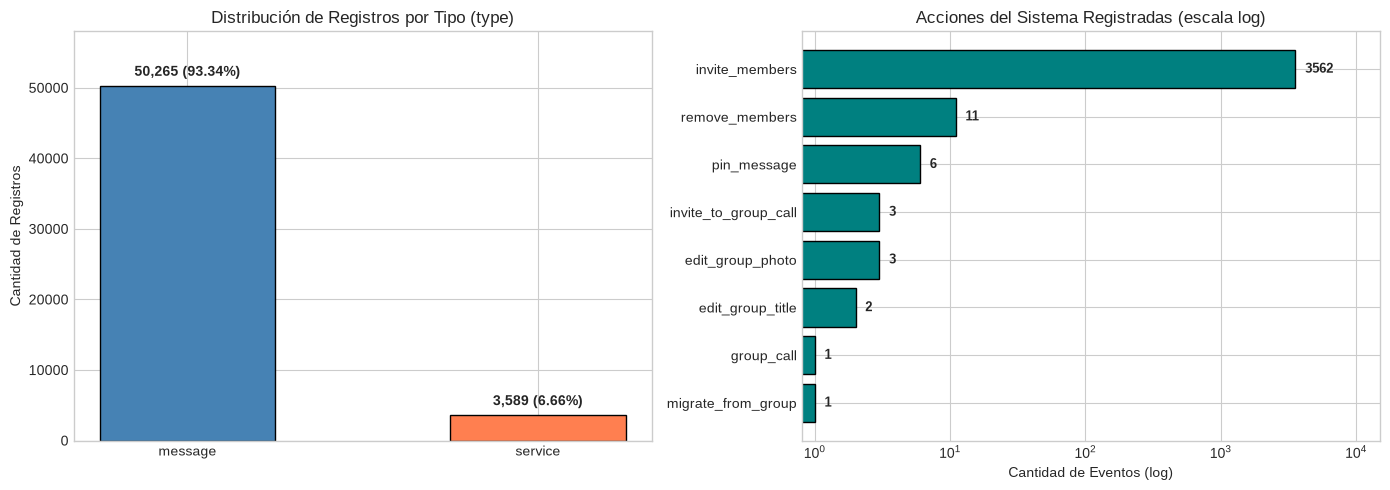

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Proporción message vs service
barras_t = axes[0].bar(conteo_type.index, conteo_type['cantidad'], color=['steelblue', 'coral'], edgecolor='black', width=0.5)
axes[0].set_title('Distribución de Registros por Tipo (type)')
axes[0].set_ylabel('Cantidad de Registros')
axes[0].set_ylim(0, 58000)
for b, pct in zip(barras_t, conteo_type['porcentaje_%']):
    h = b.get_height()
    axes[0].text(b.get_x() + b.get_width()/2, h + 1000, f"{h:,} ({pct}%)", ha='center', va='bottom', fontweight='bold')

# Gráfico 2: Desglose de acciones de servicio (escala logarítmica para apreciar todas las categorías)
acciones_ordenadas = conteo_actions.sort_values('cantidad', ascending=True)
barras_a = axes[1].barh(acciones_ordenadas.index, acciones_ordenadas['cantidad'], color='teal', edgecolor='black')
axes[1].set_xscale('log')
axes[1].set_title('Acciones del Sistema Registradas (escala log)')
axes[1].set_xlabel('Cantidad de Eventos (log)')
axes[1].set_xlim(0.8, 15000)
for b in barras_a:
    w = b.get_width()
    axes[1].text(w * 1.18, b.get_y() + b.get_height()/2, f"{int(w)}", va='center', ha='left', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

#### Significado de las 8 Acciones Registradas en el Historial:
1. invite_members (3.562 eventos - 99,25% de los servicios): Registra el ingreso de nuevos participantes al grupo (ya sea por enlace de invitación o añadidos por otro miembro), almacenando los nombres en la lista members.
2. remove_members (11 eventos): Registra la salida o expulsión de miembros del grupo.
3. pin_message (6 eventos): Registra cuando un administrador fija un mensaje importante en la parte superior del chat, vinculando el ID del mensaje objetivo en message_id.
4. edit_group_photo (3 eventos): Registra el cambio del avatar o foto identificatoria del grupo.
5. invite_to_group_call (3 eventos): Registra invitaciones directas a participantes para unirse a una llamada grupal activa.
6. edit_group_title (2 eventos): Registra modificaciones en el nombre oficial del grupo, guardando el nuevo nombre en title.
7. migrate_from_group (1 evento): Evento fundacional (registro id = 1) que documenta la conversión técnica de un grupo básico de Telegram a supergrupo público (public_supergroup).
8. group_call (1 evento): Registra la realización y duración (duration_seconds) de una conferencia de voz grupal.

## 3. Datos faltantes

- Analizar de manera visual y no visual si existen datos faltantes
- Tratar datos faltantes en el caso que los haya
- Explicar qué método se utilizó y por qué

### 3.1 Análisis No Visual de Datos Faltantes

In [6]:
faltantes = []
for columna in df.columns:
    atributo = {}
    atributo["columna"] = columna
    atributo["porcentaje"] = np.mean(df[columna].isnull()) * 100
    atributo["cantidad"] = np.sum(df[columna].isnull())
    atributo["presentes"] = np.sum(df[columna].notnull())
    faltantes.append(atributo)

faltantes_df = pd.DataFrame(faltantes).sort_values('porcentaje', ascending=False).reset_index(drop=True)
df_fl_p = faltantes_df.loc[faltantes_df['porcentaje'] > 0]

print(f"Total de columnas del DataFrame: {len(df.columns)}")
print(f"Columnas sin valores faltantes (0% nulos): {len(faltantes_df) - len(df_fl_p)} -> {faltantes_df[faltantes_df['cantidad']==0]['columna'].tolist()}")
print(f"Columnas con valores faltantes (>0% nulos): {len(df_fl_p)}")
display(df_fl_p)

Total de columnas del DataFrame: 30
Columnas sin valores faltantes (0% nulos): 6 -> ['text', 'text_entities', 'type', 'id', 'date_unixtime', 'date']
Columnas con valores faltantes (>0% nulos): 24


,columna,porcentaje,cantidad,presentes
0,contact_information,99.998143,53853,1
1,title,99.994429,53851,3
2,via_bot,99.990716,53849,5
3,poll,99.990716,53849,5
4,message_id,99.988859,53848,6
5,duration_seconds,99.810599,53752,102
6,sticker_emoji,99.450366,53558,296
7,forwarded_from,99.272106,53462,392
8,media_type,99.260965,53456,398
9,mime_type,99.244253,53447,407


In [7]:
# Verificación estructural de complementariedad entre 'from_id'/'from' (mensajes) y 'actor_id'/'actor' (servicio)
nulos_from_id_en_msg = df[df['type'] == 'message']['from_id'].isnull().sum()
nulos_actor_id_en_srv = df[df['type'] == 'service']['actor_id'].isnull().sum()
nulos_from_en_msg = df[df['type'] == 'message']['from'].isnull().sum()
nulos_actor_en_srv = df[df['type'] == 'service']['actor'].isnull().sum()

print(f"1. Nulos de 'from_id' cuando type == 'message': {nulos_from_id_en_msg} de {len(df[df['type']=='message'])}")
print(f"2. Nulos de 'actor_id' cuando type == 'service': {nulos_actor_id_en_srv} de {len(df[df['type']=='service'])}")
print(f"   -> Suma exacta de identificadores presentes (from_id + actor_id): {df['from_id'].notnull().sum()} + {df['actor_id'].notnull().sum()} = {df['from_id'].notnull().sum() + df['actor_id'].notnull().sum()} (100% de las filas)")
print(f"3. Nulos de 'from' en mensajes normales (cuentas eliminadas 'Deleted Account'): {nulos_from_en_msg}")
print(f"4. Nulos de 'actor' en eventos de servicio (cuentas eliminadas 'Deleted Account'): {nulos_actor_en_srv}")

1. Nulos de 'from_id' cuando type == 'message': 0 de 50265
2. Nulos de 'actor_id' cuando type == 'service': 0 de 3589
   -> Suma exacta de identificadores presentes (from_id + actor_id): 50265 + 3589 = 53854 (100% de las filas)
3. Nulos de 'from' en mensajes normales (cuentas eliminadas 'Deleted Account'): 6358
4. Nulos de 'actor' en eventos de servicio (cuentas eliminadas 'Deleted Account'): 765


### 3.2 Análisis Visual de Datos Faltantes

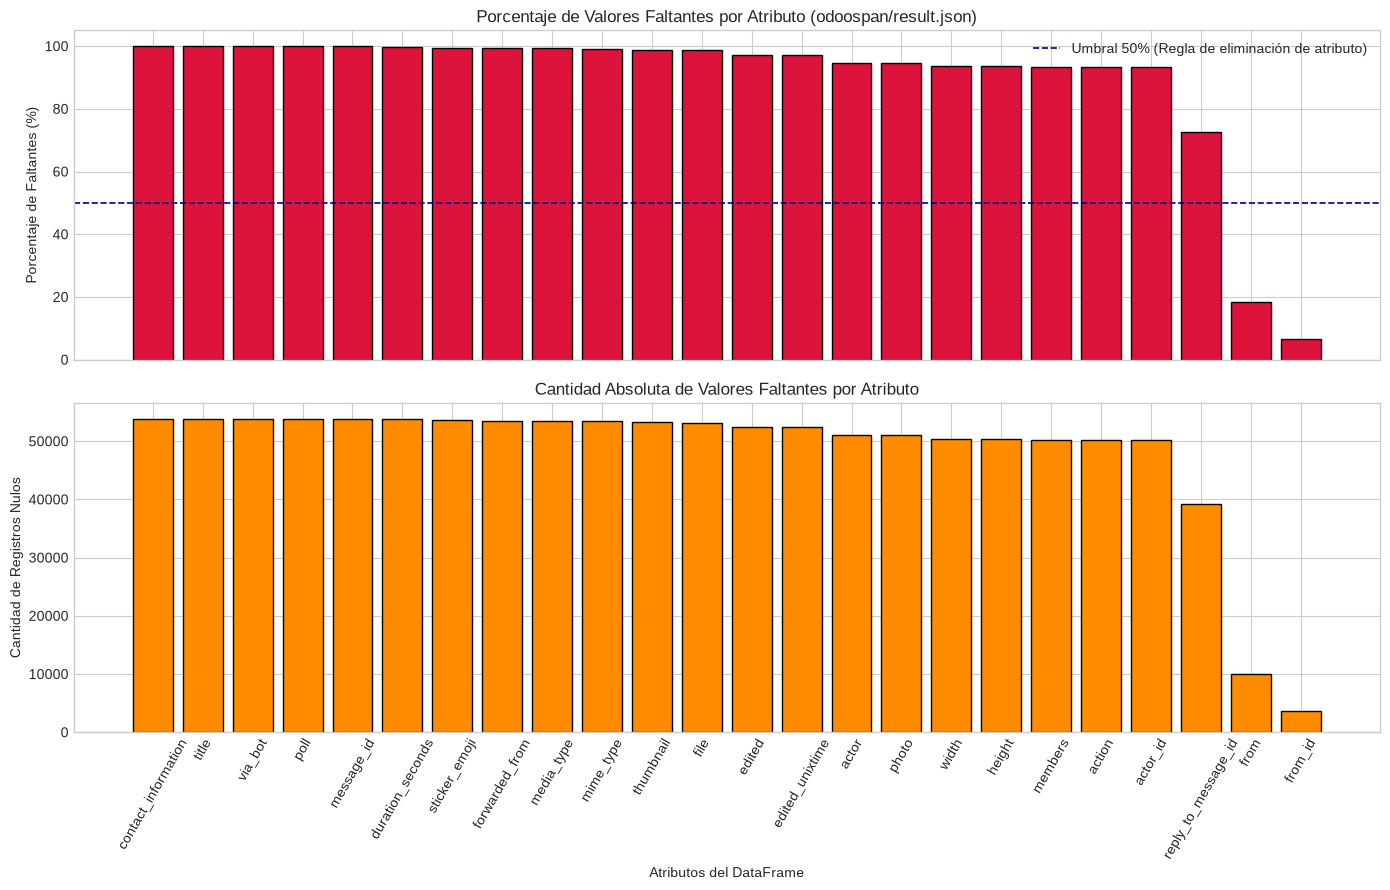

In [8]:
# 1. Gráfico de porcentaje y cantidad de datos faltantes por atributo
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

axes[0].bar(df_fl_p["columna"], df_fl_p["porcentaje"], color='crimson', edgecolor='black')
axes[0].set_ylabel('Porcentaje de Faltantes (%)')
axes[0].set_title('Porcentaje de Valores Faltantes por Atributo (odoospan/result.json)')
axes[0].axhline(50, color='navy', linestyle='--', linewidth=1.2, label='Umbral 50% (Regla de eliminación de atributo)')
axes[0].legend()

axes[1].bar(df_fl_p["columna"], df_fl_p["cantidad"], color='darkorange', edgecolor='black')
axes[1].set_ylabel('Cantidad de Registros Nulos')
axes[1].set_xlabel('Atributos del DataFrame')
axes[1].set_title('Cantidad Absoluta de Valores Faltantes por Atributo')
axes[1].tick_params(axis='x', rotation=60)

plt.tight_layout()
plt.show()

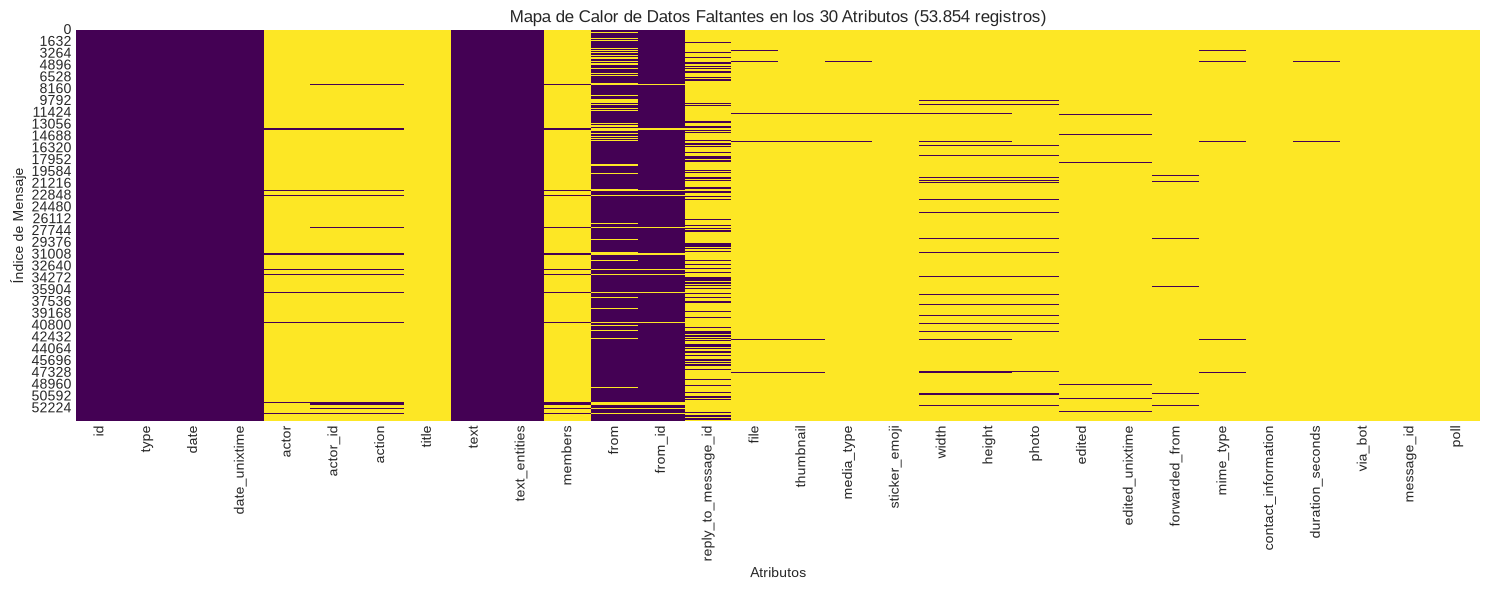

In [9]:
# 2. Mapa de calor de datos faltantes (Siguiendo Valores Faltantes.ipynb)
plt.figure(figsize=(15, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Mapa de Calor de Datos Faltantes en los 30 Atributos (53.854 registros)')
plt.xlabel('Atributos')
plt.ylabel('Índice de Mensaje')
plt.tight_layout()
plt.show()

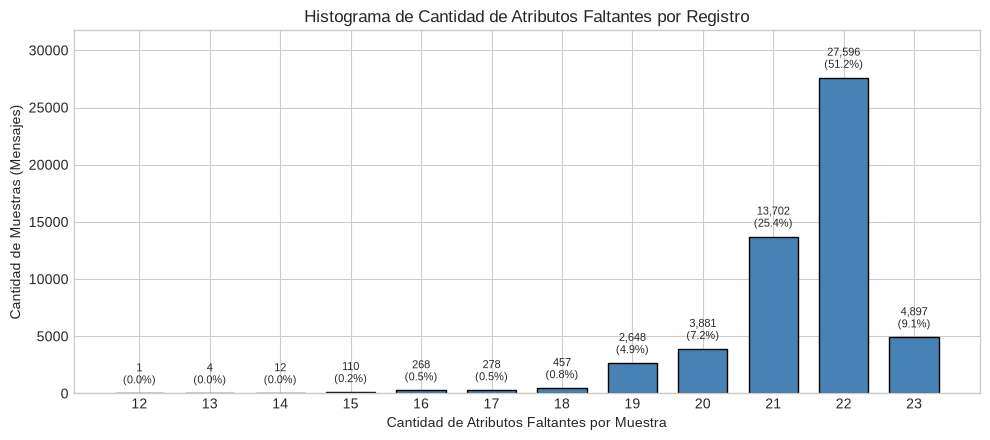

Resumen de distribución de atributos faltantes por fila:


,cantidad_muestras,porcentaje
cant_falt,,
12,1,0.00
13,4,0.01
14,12,0.02
15,110,0.20
16,268,0.50
17,278,0.52
18,457,0.85
19,2648,4.92
20,3881,7.21


In [10]:
# 3. Histograma de atributos faltantes por muestra (Siguiendo Valores Faltantes.ipynb)
df_hist = df.copy(deep=False)
df_hist['cant_falt'] = df.isnull().sum(axis=1)

plt.figure(figsize=(10, 4.5))
conteo_falt_muestra = df_hist['cant_falt'].value_counts().sort_index()
barras_h = plt.bar(conteo_falt_muestra.index, conteo_falt_muestra.values, color='steelblue', edgecolor='black', width=0.7)
plt.ylabel('Cantidad de Muestras (Mensajes)')
plt.xlabel('Cantidad de Atributos Faltantes por Muestra')
plt.title('Histograma de Cantidad de Atributos Faltantes por Registro')
plt.xticks(conteo_falt_muestra.index)
plt.ylim(0, max(conteo_falt_muestra.values) * 1.15)

for b in barras_h:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2, h + 600, f"{h:,}\n({h/len(df)*100:.1f}%)", ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

print("Resumen de distribución de atributos faltantes por fila:")
display(conteo_falt_muestra.to_frame('cantidad_muestras').assign(porcentaje=lambda x: (x['cantidad_muestras']/len(df)*100).round(2)))

### 3.3 Tratamiento de Datos Faltantes y Justificación Metodológica

Del análisis anterior se desprende que todos los registros tienen entre 17 y 23 atributos nulos simultáneamente (con moda en 22 atributos nulos por fila, que corresponde al 54,4% del dataset). Esto ocurre porque el archivo result.json proviene de un modelo semi-estructurado (documental/polimórfico): cada tipo de evento (message de texto, respuesta, imagen, audio, encuesta o acción service) utiliza únicamente un subconjunto de claves JSON, dejando el resto como NaN al tabularse en un DataFrame relacional.

Por consiguiente, si se aplicara eliminación de muestras (dropna), se perdería el 100% del dataset. En su lugar, aplicando las reglas metodológicas de la cátedra (Valores Faltantes.ipynb) y prevención de sesgos, se implementa una estrategia en tres pasos:

1. Deducción Determinística / Consolidación de Autoría (from_id y from):
   - Como se demostró en la sección 3.1, los 3.589 valores faltantes de from_id (6,66%) ocurren exactamente cuando type == 'service', donde Telegram almacena el identificador en actor_id. Al consolidar from_id = from_id.fillna(actor_id), se recupera el 100% de los identificadores de emisor sin necesidad de estimación estadística.
   - Análogamente, para from (18,47% de nulos), se consolida primero con actor en los registros de servicio, recuperando de manera exacta 2.824 nombres de usuario.

2. Imputación por Constante Global ('Cuenta Eliminada') para Cuentas Borradas en from:
   - Los 7.123 registros restantes con from nulo (6.358 mensajes normales + 765 acciones de servicio) poseen un from_id válido (ej. user428593), pero carecen de nombre porque el usuario eliminó su cuenta de Telegram (Deleted Account).
   - Por qué no usar la Moda: Imputar una variable nominal de autoría con la moda ('Erick Navarro') adjudicaría falsamente 7.123 mensajes a una sola persona, introduciendo un grave sesgo de medición y atribución.
   - Por qué usar Constante Global: De acuerdo con Valores Faltantes.ipynb, se reemplazan dichos nulos con la etiqueta explícita 'Cuenta Eliminada', preservando la trazabilidad por from_id y el 100% de las muestras.

3. Eliminación de Atributos con Faltantes > 50% (y Preservación de Subtablas Especializadas):
   - Siguiendo la regla de Valores Faltantes.ipynb (filtrar y eliminar aquellos atributos cuyo porcentaje de valores faltantes sea mayor al 50%), los 22 atributos opcionales de eventos específicos o adjuntos multimedia superan el 72% de nulos (72,70% a 99,998%). Se eliminan del DataFrame general de conversación (df_sin_atributos), obteniendo una tabla relacional limpia con 0% de nulos.
   - Asimismo, para no perder los atributos cuantitativos de metadatos (reply_to_message_id, width, height, duration_seconds, message_id, edited_unixtime) que solo existen en mensajes con adjuntos o respuestas, se conserva el acceso a sus registros válidos para el análisis estadístico de Outliers de la Sección 4.

In [11]:
# Copia de trabajo para tratamiento de datos faltantes
df_tratado = df.copy(deep=True)

# Paso 1: Imputación determinística de 'from_id' y 'from' a partir de 'actor_id' y 'actor'
df_tratado['from_id'] = df_tratado['from_id'].fillna(df_tratado['actor_id'])
df_tratado['from'] = df_tratado['from'].fillna(df_tratado['actor'])

print(f"Nulos en 'from_id' tras consolidar con 'actor_id': {df_tratado['from_id'].isnull().sum()}")
print(f"Nulos restantes en 'from' (cuentas eliminadas de Telegram): {df_tratado['from'].isnull().sum()}")

# Paso 2: Imputación por Constante Global en 'from'
df_tratado['from'] = df_tratado['from'].fillna('Cuenta Eliminada')
print(f"Nulos en 'from' tras aplicar Constante Global: {df_tratado['from'].isnull().sum()}")

# Paso 3: Eliminación de atributos con porcentaje de faltantes > 50% (Regla de Valores Faltantes.ipynb)
columnas_mas_50_nulos = df_fl_p.loc[df_fl_p['porcentaje'] > 50, 'columna'].tolist()
df_limpio = df_tratado.drop(columns=columnas_mas_50_nulos)

print(f"\nAtributos eliminados por superar el 50% de nulos ({len(columnas_mas_50_nulos)} columnas):")
print(columnas_mas_50_nulos)
print(f"\nDimensiones del DataFrame general limpio (df_limpio): {df_limpio.shape}")
print(f"Total de valores nulos en df_limpio: {df_limpio.isnull().sum().sum()}")
display(df_limpio.head())

Nulos en 'from_id' tras consolidar con 'actor_id': 0
Nulos restantes en 'from' (cuentas eliminadas de Telegram): 7123
Nulos en 'from' tras aplicar Constante Global: 0

Atributos eliminados por superar el 50% de nulos (22 columnas):
['contact_information', 'title', 'via_bot', 'poll', 'message_id', 'duration_seconds', 'sticker_emoji', 'forwarded_from', 'media_type', 'mime_type', 'thumbnail', 'file', 'edited', 'edited_unixtime', 'actor', 'photo', 'width', 'height', 'members', 'action', 'actor_id', 'reply_to_message_id']

Dimensiones del DataFrame general limpio (df_limpio): (53854, 8)
Total de valores nulos en df_limpio: 0


,id,type,date,date_unixtime,text,text_entities,from,from_id
0,1,service,2017-01-19T23:54:30,1484880870,,[],Odoo en español,channel1079744014
1,2,service,2017-01-20T00:22:03,1484882523,,[],Diego C,user178657984
2,3,message,2017-01-20T00:22:21,1484882541,Hola,"[{'type': 'plain', 'text': 'Hola'}]",Erick Navarro,user1876572
3,4,message,2017-01-20T00:22:59,1484882579,Hola a todos,"[{'type': 'plain', 'text': 'Hola a todos'}]",Cuenta Eliminada,user219168707
4,5,message,2017-01-20T00:23:51,1484882631,👋,"[{'type': 'plain', 'text': '👋'}]",Erick Navarro,user1876572


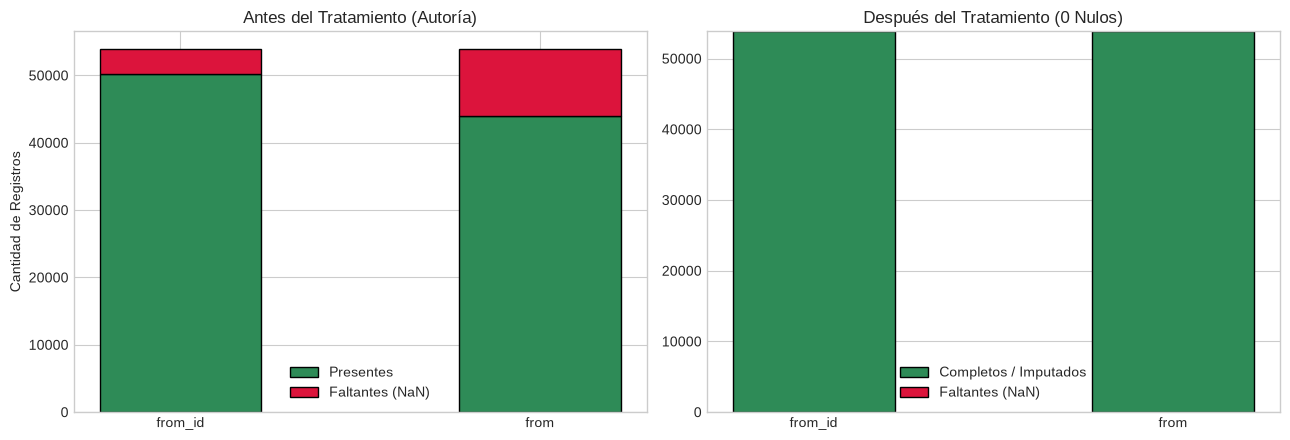

In [12]:
# Comparación visual Antes vs. Después en los atributos de autoría ('from' y 'from_id')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

nulos_antes = [df['from_id'].isnull().sum(), df['from'].isnull().sum()]
presentes_antes = [df['from_id'].notnull().sum(), df['from'].notnull().sum()]

nulos_despues = [df_limpio['from_id'].isnull().sum(), df_limpio['from'].isnull().sum()]
presentes_despues = [df_limpio['from_id'].notnull().sum(), df_limpio['from'].notnull().sum()]

x = np.arange(2)
etiquetas = ['from_id', 'from']

axes[0].bar(x, presentes_antes, label='Presentes', color='seagreen', edgecolor='black', width=0.45)
axes[0].bar(x, nulos_antes, bottom=presentes_antes, label='Faltantes (NaN)', color='crimson', edgecolor='black', width=0.45)
axes[0].set_xticks(x)
axes[0].set_xticklabels(etiquetas)
axes[0].set_ylabel('Cantidad de Registros')
axes[0].set_title('Antes del Tratamiento (Autoría)')
axes[0].legend()

axes[1].bar(x, presentes_despues, label='Completos / Imputados', color='seagreen', edgecolor='black', width=0.45)
axes[1].bar(x, nulos_despues, bottom=presentes_despues, label='Faltantes (NaN)', color='crimson', edgecolor='black', width=0.45)
axes[1].set_xticks(x)
axes[1].set_xticklabels(etiquetas)
axes[1].set_title('Después del Tratamiento (0 Nulos)')
axes[1].legend()

plt.tight_layout()
plt.show()

## 4. Outliers

- Analizar de manera visual y no visual si existen valores atípicos para cada valor no categórico
- Si existen valores atípicos, ¿estos son causados por errores en la carga de datos o por otra razón?. Explicar la razón

### 4.1 Identificación de Atributos No Categóricos y Análisis No Visual (Estadísticos e IQR Score)

Para realizar una auditoría exhaustiva sobre cada valor no categórico del dataset original, se evalúan tanto las 6 variables numéricas nativas (int64 / float64) como las 2 marcas de tiempo Unix (date_unixtime y edited_unixtime, almacenadas como cadenas numéricas en el JSON):
1. id: Identificador secuencial del mensaje (int64).
2. reply_to_message_id: Identificador del mensaje respondido (float64).
3. width: Ancho en píxeles de contenido visual (float64).
4. height: Alto en píxeles de contenido visual (float64).
5. duration_seconds: Duración en segundos de audios, videos o animaciones (float64).
6. message_id: Identificador del mensaje fijado en acciones pin_message (float64).
7. date_unixtime: Timestamp Unix de publicación convertido a numérico (int64).
8. edited_unixtime: Timestamp Unix de edición convertido a numérico (float64).

In [13]:
# Construcción del DataFrame de atributos no categóricos (numéricos)
cols_no_categoricas = [
    'id',
    'reply_to_message_id',
    'width',
    'height',
    'duration_seconds',
    'message_id',
    'date_unixtime',
    'edited_unixtime'
]

df_num = df[cols_no_categoricas].copy()
df_num['date_unixtime'] = pd.to_numeric(df_num['date_unixtime'], errors='coerce')
df_num['edited_unixtime'] = pd.to_numeric(df_num['edited_unixtime'], errors='coerce')

print("Características estadísticas descriptivas de los atributos no categóricos:")
display(df_num.describe().T)

Características estadísticas descriptivas de los atributos no categóricos:


,count,mean,std,min,25%,50%,75%,max
id,53854.0,3.093325e+04,1.926220e+04,1.000000e+00,1.367425e+04,2.901850e+04,4.855575e+04,6.448100e+04
reply_to_message_id,14703.0,3.525968e+04,1.886749e+04,2.000000e+00,1.787650e+04,3.738900e+04,5.234750e+04,6.446900e+04
width,3439.0,9.496490e+02,3.760842e+02,6.400000e+01,6.180000e+02,9.820000e+02,1.280000e+03,4.502000e+03
height,3439.0,5.375961e+02,3.318614e+02,2.100000e+01,2.855000e+02,5.120000e+02,7.200000e+02,4.819000e+03
duration_seconds,102.0,3.003922e+01,4.559940e+01,1.000000e+00,3.000000e+00,9.500000e+00,3.675000e+01,2.710000e+02
message_id,6.0,1.093933e+04,3.830829e+03,6.617000e+03,7.681000e+03,1.119950e+04,1.398525e+04,1.519800e+04
date_unixtime,53854.0,1.598204e+09,4.825789e+07,1.484881e+09,1.557165e+09,1.601399e+09,1.643970e+09,1.667855e+09
edited_unixtime,1444.0,1.629148e+09,4.252856e+07,1.484965e+09,1.603887e+09,1.648978e+09,1.658671e+09,1.667841e+09


In [14]:
# Cálculo de Q1, Q3, IQR, rangos normales y conteo de valores atípicos (Metodología de Outliers.ipynb)
Q1 = df_num.quantile(0.25)
Q3 = df_num.quantile(0.75)
IQR = Q3 - Q1

rango_inferior = Q1 - 1.5 * IQR
rango_superior = Q3 + 1.5 * IQR

# Matriz booleana de outliers (evaluada sobre valores presentes no nulos)
df_outliers = (df_num < rango_inferior) | (df_num > rango_superior)

resumen_iqr = []
for col in cols_no_categoricas:
    validos = df_num[col].dropna()
    cant_out = int(df_outliers[col].sum())
    cant_inf = int((df_num[col] < rango_inferior[col]).sum())
    cant_sup = int((df_num[col] > rango_superior[col]).sum())
    resumen_iqr.append({
        'atributo': col,
        'n_validos': len(validos),
        'Q1 (25%)': round(Q1[col], 2),
        'Mediana (50%)': round(validos.median(), 2),
        'Q3 (75%)': round(Q3[col], 2),
        'IQR': round(IQR[col], 2),
        'rango_inferior': round(rango_inferior[col], 2),
        'rango_superior': round(rango_superior[col], 2),
        'outliers_inf': cant_inf,
        'outliers_sup': cant_sup,
        'total_outliers': cant_out,
        'porcentaje_outliers_%': round(cant_out / len(validos) * 100, 2)
    })

df_resumen_iqr = pd.DataFrame(resumen_iqr)
display(df_resumen_iqr)

,atributo,n_validos,Q1 (25%),Mediana (50%),Q3 (75%),IQR,rango_inferior,rango_superior,outliers_inf,outliers_sup,total_outliers,porcentaje_outliers_%
0,id,53854,1.367425e+04,2.901850e+04,4.855575e+04,34881.50,-3.864800e+04,1.008780e+05,0,0,0,0.00
1,reply_to_message_id,14703,1.787650e+04,3.738900e+04,5.234750e+04,34471.00,-3.383000e+04,1.040540e+05,0,0,0,0.00
2,width,3439,6.180000e+02,9.820000e+02,1.280000e+03,662.00,-3.750000e+02,2.273000e+03,0,7,7,0.20
3,height,3439,2.855000e+02,5.120000e+02,7.200000e+02,434.50,-3.662500e+02,1.371750e+03,0,11,11,0.32
4,duration_seconds,102,3.000000e+00,9.500000e+00,3.675000e+01,33.75,-4.762000e+01,8.738000e+01,0,13,13,12.75
5,message_id,6,7.681000e+03,1.119950e+04,1.398525e+04,6304.25,-1.775380e+03,2.344162e+04,0,0,0,0.00
6,date_unixtime,53854,1.557165e+09,1.601399e+09,1.643970e+09,86804800.75,1.426958e+09,1.774177e+09,0,0,0,0.00
7,edited_unixtime,1444,1.603887e+09,1.648978e+09,1.658671e+09,54784146.25,1.521711e+09,1.740848e+09,18,0,18,1.25


### 4.2 Análisis Visual de Valores Atípicos

Siguiendo las técnicas gráficas de Outliers.ipynb, se inspeccionan los atributos no categóricos mediante:
1. Mapa de calor (Heatmap) de la matriz booleana df_outliers.
2. Diagramas de caja (Box Plot) individuales para los 8 atributos no categóricos.
3. Diagramas de caja segmentados por categoría (media_type / mime_type).
4. Gráficos de dispersión (Scatter Plot) e Histogramas de frecuencia (Histogram).

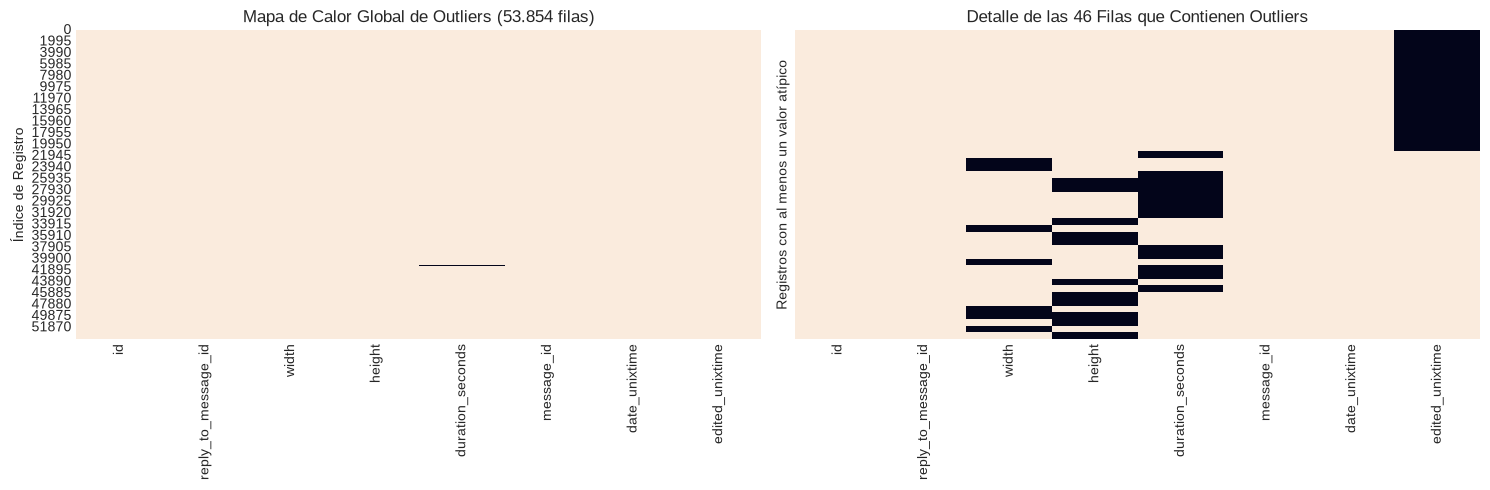

In [15]:
# 1. Mapa de calor para identificar los valores atípicos (sobre subconjunto con al menos un atributo multimedia/edición o muestra general)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1a. Mapa de calor global sobre todos los registros
sns.heatmap(df_outliers, cbar=False, cmap='rocket_r', ax=axes[0])
axes[0].set_title('Mapa de Calor Global de Outliers (53.854 filas)')
axes[0].set_ylabel('Índice de Registro')

# 1b. Mapa de calor enfocado en las filas que contienen al menos un outlier
filas_con_outlier = df_outliers[df_outliers.any(axis=1)]
sns.heatmap(filas_con_outlier, cbar=False, cmap='rocket_r', ax=axes[1], yticklabels=False)
axes[1].set_title(f'Detalle de las {len(filas_con_outlier)} Filas que Contienen Outliers')
axes[1].set_ylabel('Registros con al menos un valor atípico')

plt.tight_layout()
plt.show()

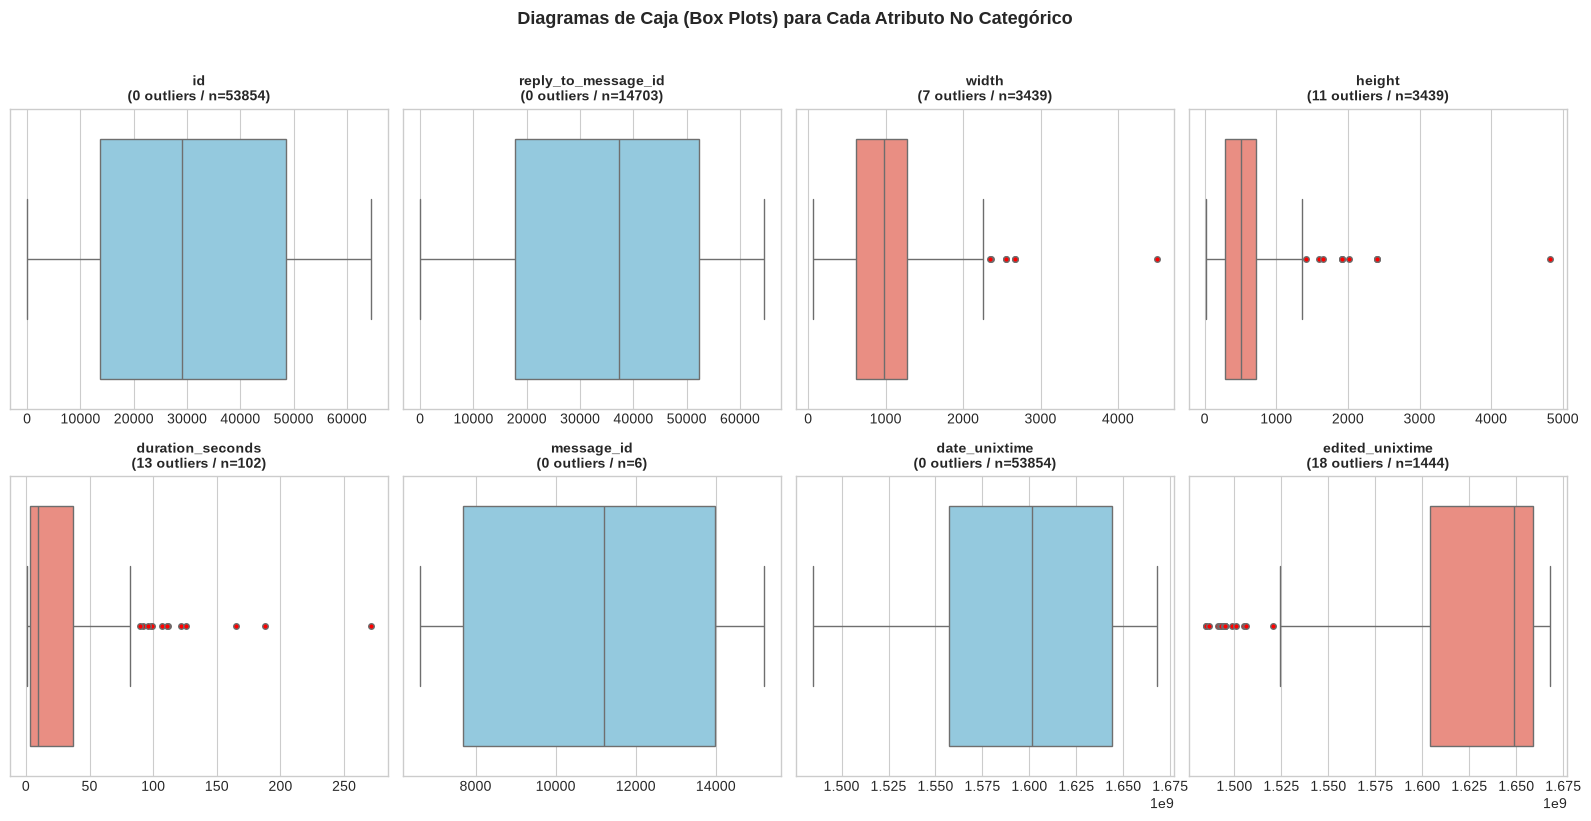

In [16]:
# 2. Box plots individuales para cada uno de los 8 atributos no categóricos
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

colores_box = ['steelblue', 'steelblue', 'coral', 'coral', 'crimson', 'steelblue', 'steelblue', 'amber']

for i, col in enumerate(cols_no_categoricas):
    serie = df_num[col].dropna()
    cant_out = df_outliers[col].sum()
    color_actual = 'salmon' if cant_out > 0 else 'skyblue'
    sns.boxplot(x=serie, ax=axes[i], color=color_actual, flierprops=dict(marker='o', markersize=4, markerfacecolor='red'))
    axes[i].set_title(f"{col}\n({cant_out} outliers / n={len(serie)})", fontsize=10, fontweight='bold')
    axes[i].set_xlabel('')

plt.suptitle('Diagramas de Caja (Box Plots) para Cada Atributo No Categórico', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

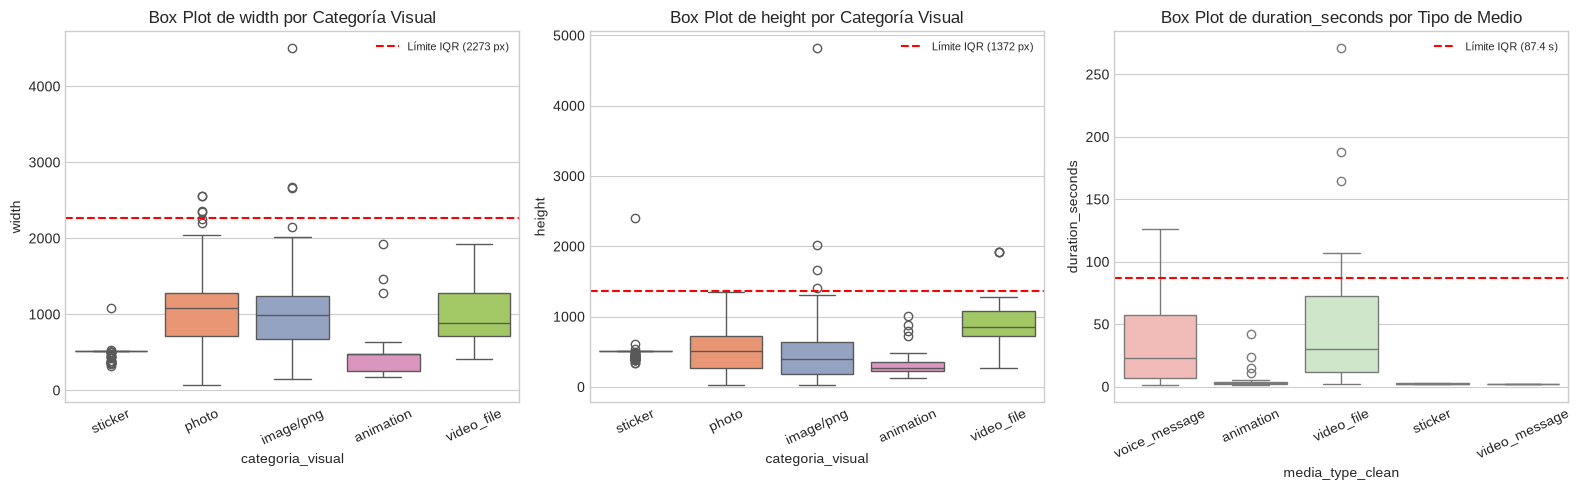

In [17]:
# 3. Box plots divididos por categoría (Siguiendo Outliers.ipynb)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 3a. width según tipo de medio / imagen
df_media = df.copy()
df_media['categoria_visual'] = df_media['media_type'].fillna(
    pd.Series(np.where(df_media['photo'].notnull(), 'photo', df_media['mime_type']), index=df_media.index)
)
top_visual = df_media[df_media['width'].notnull()]['categoria_visual'].value_counts().head(5).index
df_vis_sub = df_media[df_media['categoria_visual'].isin(top_visual)]

sns.boxplot(data=df_vis_sub, x='categoria_visual', y='width', ax=axes[0], palette='Set2')
axes[0].set_title('Box Plot de width por Categoría Visual')
axes[0].tick_params(axis='x', rotation=25)
axes[0].axhline(rango_superior['width'], color='red', linestyle='--', label=f"Límite IQR ({rango_superior['width']:.0f} px)")
axes[0].legend(fontsize=8)

# 3b. height según tipo de medio / imagen
sns.boxplot(data=df_vis_sub, x='categoria_visual', y='height', ax=axes[1], palette='Set2')
axes[1].set_title('Box Plot de height por Categoría Visual')
axes[1].tick_params(axis='x', rotation=25)
axes[1].axhline(rango_superior['height'], color='red', linestyle='--', label=f"Límite IQR ({rango_superior['height']:.0f} px)")
axes[1].legend(fontsize=8)

# 3c. duration_seconds según media_type
df_dur_sub = df[df['duration_seconds'].notnull()].copy()
df_dur_sub['media_type_clean'] = df_dur_sub['media_type'].fillna(df_dur_sub['action'].fillna('video/otros'))
sns.boxplot(data=df_dur_sub, x='media_type_clean', y='duration_seconds', ax=axes[2], palette='Pastel1')
axes[2].set_title('Box Plot de duration_seconds por Tipo de Medio')
axes[2].tick_params(axis='x', rotation=25)
axes[2].axhline(rango_superior['duration_seconds'], color='red', linestyle='--', label=f"Límite IQR ({rango_superior['duration_seconds']:.1f} s)")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

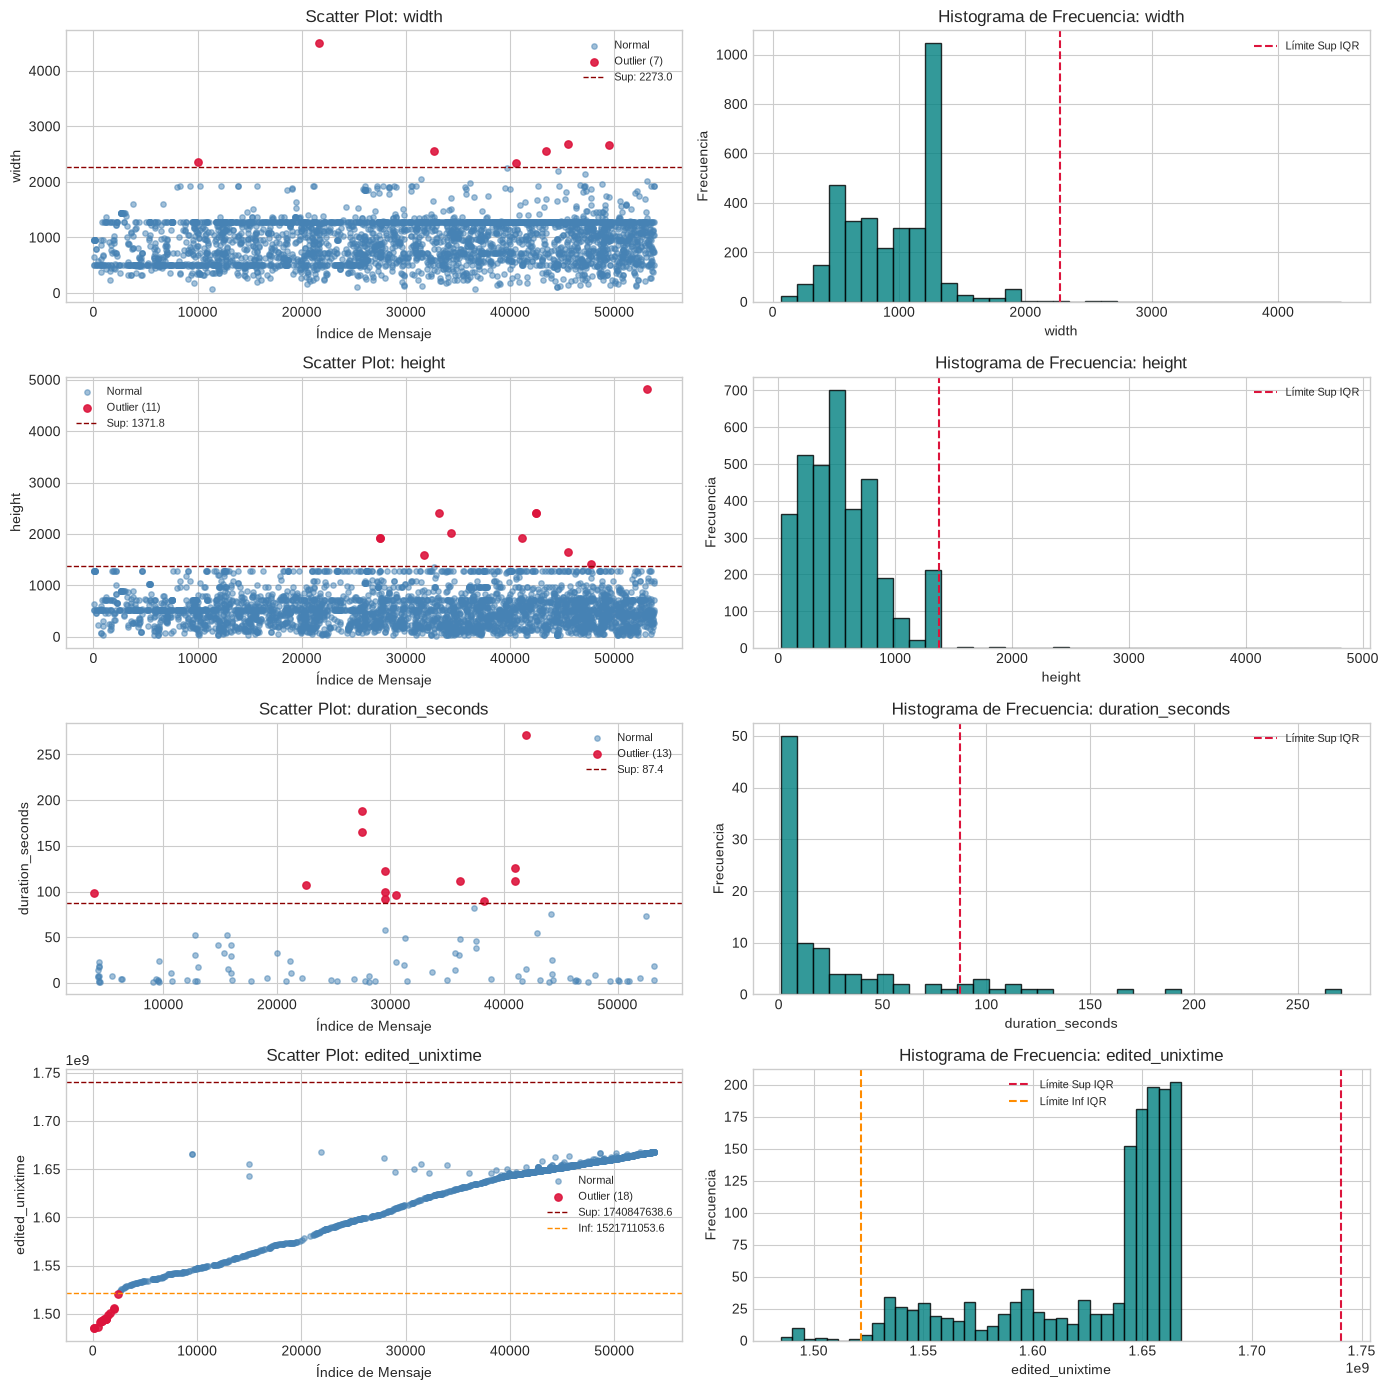

In [18]:
# 4. Scatter Plots e Histogramas de los 4 atributos que presentan valores atípicos
atributos_con_outliers = ['width', 'height', 'duration_seconds', 'edited_unixtime']

fig, axes = plt.subplots(4, 2, figsize=(14, 14))

for idx, col in enumerate(atributos_con_outliers):
    serie = df_num[col].dropna()
    lim_inf = rango_inferior[col]
    lim_sup = rango_superior[col]
    es_out = (serie < lim_inf) | (serie > lim_sup)
    
    # Scatter Plot
    axes[idx, 0].scatter(serie.index[~es_out], serie[~es_out], alpha=0.5, s=15, color='steelblue', label='Normal')
    axes[idx, 0].scatter(serie.index[es_out], serie[es_out], alpha=0.9, s=28, color='crimson', label=f'Outlier ({es_out.sum()})')
    if lim_sup < serie.max() * 1.2:
        axes[idx, 0].axhline(lim_sup, color='darkred', linestyle='--', linewidth=1, label=f'Sup: {lim_sup:.1f}')
    if lim_inf > serie.min() * 0.8:
        axes[idx, 0].axhline(lim_inf, color='darkorange', linestyle='--', linewidth=1, label=f'Inf: {lim_inf:.1f}')
    axes[idx, 0].set_title(f'Scatter Plot: {col}')
    axes[idx, 0].set_xlabel('Índice de Mensaje')
    axes[idx, 0].set_ylabel(col)
    axes[idx, 0].legend(fontsize=8)
    
    # Histograma
    axes[idx, 1].hist(serie, bins=35, color='teal', edgecolor='black', alpha=0.8)
    if lim_sup < serie.max() * 1.2:
        axes[idx, 1].axvline(lim_sup, color='crimson', linestyle='--', linewidth=1.5, label=f'Límite Sup IQR')
    if lim_inf > serie.min() * 0.8:
        axes[idx, 1].axvline(lim_inf, color='darkorange', linestyle='--', linewidth=1.5, label=f'Límite Inf IQR')
    axes[idx, 1].set_title(f'Histograma de Frecuencia: {col}')
    axes[idx, 1].set_xlabel(col)
    axes[idx, 1].set_ylabel('Frecuencia')
    axes[idx, 1].legend(fontsize=8)

plt.tight_layout()
plt.show()

### 4.3 Inspección de Casos Extremos y Explicación de su Causa

- Si existen valores atípicos, ¿estos son causados por errores en la carga de datos o por otra razón?. Explicar la razón

In [19]:
print("1. Registros detectados como outliers en 'width' (> 2.273 px):")
display(df.loc[df_outliers['width'], ['id', 'date', 'from', 'mime_type', 'photo', 'width', 'height']])

print("\n2. Registros detectados como outliers en 'height' (> 1.371,75 px):")
display(df.loc[df_outliers['height'], ['id', 'date', 'from', 'media_type', 'mime_type', 'width', 'height', 'duration_seconds']])

print("\n3. Registros detectados como outliers en 'duration_seconds' (> 87,375 s):")
display(df.loc[df_outliers['duration_seconds'], ['id', 'date', 'from', 'media_type', 'mime_type', 'duration_seconds', 'width', 'height']])

print("\n4. Muestra de registros detectados como outliers en 'edited_unixtime' (< 1.521.711.053,6 -> antes de marzo 2018):")
display(df.loc[df_outliers['edited_unixtime'], ['id', 'date', 'edited', 'edited_unixtime', 'from']].head(8))

1. Registros detectados como outliers en 'width' (> 2.273 px):


,id,date,from,mime_type,photo,width,height
10060,10232,2019-01-11T04:38:32,Kike,NaN,(File not included. Change data exporting sett...,2354.0,812.0
21626,22792,2020-03-10T10:47:29,®,image/png,NaN,4502.0,406.0
32729,38811,2021-06-03T13:11:01,Daniel,NaN,(File not included. Change data exporting sett...,2560.0,1355.0
40610,48780,2022-02-10T07:16:16,Isaag G,NaN,(File not included. Change data exporting sett...,2342.0,1128.0
43410,51946,2022-04-04T12:37:58,Luis,NaN,(File not included. Change data exporting sett...,2560.0,855.0
45602,54470,2022-05-16T12:25:14,Nasko,image/png,NaN,2676.0,1658.0
49462,58827,2022-08-02T08:47:32,Nasko,image/png,NaN,2666.0,944.0



2. Registros detectados como outliers en 'height' (> 1.371,75 px):


,id,date,from,media_type,mime_type,width,height,duration_seconds
27485,29850,2020-10-12T21:36:20,Ing William Consultor Odoo,video_file,video/mp4,886.0,1920.0,165.0
27500,29876,2020-10-12T21:42:30,Ing William Consultor Odoo,video_file,video/mp4,886.0,1920.0,188.0
31740,37198,2021-04-28T23:08:34,Wilder Hernández García,NaN,image/jpeg,1200.0,1600.0,NaN
33199,39566,2021-06-20T10:34:59,Carlos Lopez,sticker,NaN,1080.0,2400.0,NaN
34374,41104,2021-08-03T14:41:04,Rosselyn BC,NaN,image/png,1512.0,2016.0,NaN
41197,49391,2022-02-20T16:13:09,Coco  Trader Cr,video_file,video/mp4,880.0,1920.0,7.0
42466,50785,2022-03-18T08:35:05,Carlos Pirelli,NaN,image/jpeg,1080.0,2400.0,NaN
42490,50812,2022-03-18T16:50:02,Carlos Pirelli,NaN,image/jpeg,1080.0,2400.0,NaN
45602,54470,2022-05-16T12:25:14,Nasko,NaN,image/png,2676.0,1658.0,NaN
47734,56862,2022-07-04T06:41:18,Nasko,NaN,image/png,1868.0,1414.0,NaN



3. Registros detectados como outliers en 'duration_seconds' (> 87,375 s):


,id,date,from,media_type,mime_type,duration_seconds,width,height
3845,3865,2018-07-09T14:59:55,Yasmany Castillo,voice_message,audio/ogg,98.0,NaN,NaN
22532,23799,2020-05-01T13:24:17,A&C Sistemas - Juan Ayala,video_file,video/mp4,107.0,1116.0,836.0
27485,29850,2020-10-12T21:36:20,Ing William Consultor Odoo,video_file,video/mp4,165.0,886.0,1920.0
27500,29876,2020-10-12T21:42:30,Ing William Consultor Odoo,video_file,video/mp4,188.0,886.0,1920.0
29506,33268,2021-01-19T13:02:56,Felipe Soto Herrera,voice_message,audio/ogg,92.0,NaN,NaN
29508,33270,2021-01-19T13:22:23,Felipe Soto Herrera,voice_message,audio/ogg,122.0,NaN,NaN
29517,33283,2021-01-19T17:24:22,Felipe Soto Herrera,voice_message,audio/ogg,99.0,NaN,NaN
30499,34895,2021-02-24T00:13:08,Felipe Soto Herrera,voice_message,audio/ogg,96.0,NaN,NaN
36093,43245,2021-09-26T15:10:02,Yanine Certaiin,voice_message,audio/ogg,112.0,NaN,NaN
38202,46011,2021-12-06T20:20:30,Felipe Soto Herrera,voice_message,audio/ogg,90.0,NaN,NaN



4. Muestra de registros detectados como outliers en 'edited_unixtime' (< 1.521.711.053,6 -> antes de marzo 2018):


,id,date,edited,edited_unixtime,from
69,70,2017-01-20T23:20:15,2017-01-20T23:20:24,1484965224,Erick Navarro
78,79,2017-01-20T23:22:18,2017-01-20T23:22:22,1484965342,Erick Navarro
476,477,2017-02-06T13:26:03,2017-02-06T13:29:56,1486398596,Erick Navarro
716,717,2017-04-04T20:53:09,2017-04-04T20:53:18,1491349998,Erick Navarro
820,823,2017-04-18T09:41:22,2017-04-18T09:41:29,1492519289,Pasankalla
868,872,2017-04-20T18:09:13,2017-04-20T18:10:51,1492722651,Pasankalla
869,873,2017-04-20T18:09:54,2017-04-20T18:11:06,1492722666,Pasankalla
1036,1041,2017-05-11T08:18:43,2017-05-11T08:23:32,1494501812,Pasankalla


#### Diagnóstico Técnico: ¿Errores de Carga o Varianza Real del Dominio?

A partir de la evidencia empírica recolectada, se concluye que los valores atípicos detectados NO son causados por errores en la carga o recolección de datos, sino que obedecen a varianza real y legítima en el comportamiento de los usuarios y la evolución temporal de la comunidad:

1. Ausencia de Errores de Carga (Ingesta Automatizada por Sistema):
   - A diferencia de los datasets tabulados manualmente donde ocurren errores de tipeo o de separador decimal (como en winequality-red.csv visto en Outliers.ipynb, donde valores como 997.0 en density o 645.0 en volatile acidity se debían a errores de escala), el archivo result.json es generado automáticamente por el motor de exportación de Telegram.
   - Los atributos cuantitativos (width, height, duration_seconds, edited_unixtime) son extraídos de forma directa de los encabezados binarios de los archivos (PNG, JPEG, MP4, OGG) y de las marcas de tiempo del servidor central.

2. Razón Específica en width (7 outliers entre 2.342 px y 4.502 px):
   - El rango intercuartílico (Q1 = 618 px, Q3 = 1.280 px) está dominado por imágenes estándar comprimidas por Telegram (1280×720) y stickers (512×512).
   - Los 7 valores atípicos corresponden a capturas de pantalla de escritorio enviadas sin compresión (image/png) o desde monitores de alta resolución (2K/QHD 2560×1355, Retina 2676×1658) y configuraciones de doble monitor / ultrawide (4502×406 px, mensaje id=22792), habituales en un grupo de soporte técnico de Odoo ERP donde los desarrolladores comparten trazas de código y vistas anchas del sistema.

3. Razón Específica en height (11 outliers entre 1.414 px y 4.819 px):
   - Mientras la mayoría de las capturas son horizontales (mediana de alto = 512 px), los 11 outliers corresponden a capturas y grabaciones de pantalla en orientación vertical desde teléfonos móviles modernos con relación de aspecto alargada (886×1920 px en video/mp4, 1080×2400 px en image/jpeg), además de una captura de desplazamiento completo (scrolling screenshot) de 2023×4819 px (id=63626) tomada para mostrar un formulario o reporte extenso completo.

4. Razón Específica en duration_seconds (13 outliers entre 90 s y 271 s):
   - El 75% de los archivos con duración dura menos de 36,75 segundos (predominio de GIFs/animaciones cortas de 1 a 5 s y audios breves, con mediana de 9,5 s).
   - Los 13 valores atípicos corresponden a notas de voz explicativas extensas (voice_message en formato audio/ogg de 90 a 126 s) y videos demostrativos (video_file en formato video/mp4 de 107 a 271 s, es decir, hasta 4,5 minutos) donde miembros de la comunidad graban su pantalla reproduciendo un problema funcional o explicando un flujo completo en Odoo.

5. Razón Específica en edited_unixtime (18 outliers inferiores entre enero 2017 y marzo 2018):
   - El grupo se fundó en enero de 2017 con baja actividad inicial y experimentó un crecimiento exponencial entre 2020 y 2022, concentrando allí los cuartiles Q1 y Q3 de los mensajes editados. Por esa asimetría temporal (cola izquierda), las 18 ediciones legítimas realizadas durante el primer año de vida de la comunidad quedan por debajo de Q1 - 1.5 * IQR.

### 4.4 Evaluación Comparativa de Métodos de Tratamiento (Outliers.ipynb)

Aunque los valores atípicos detectados representan varianza legítima del dominio (y no errores de carga), ciertos algoritmos de Machine Learning o visualización pueden verse afectados por la fuerte asimetría positiva de variables como duration_seconds y width. A continuación se implementan y comparan los cuatro métodos de tratamiento de la cátedra (Outliers.ipynb) sobre duration_seconds:
1. Flooring and Capping basado en cuartiles/percentiles (P10 y P90).
2. Trimming (recorte de extremos fuera de P02 y P98).
3. Eliminación por IQR Score (descarte de registros fuera de [Q1 - 1.5 * IQR, Q3 + 1.5 * IQR]).
4. Transformación Logarítmica (np.log).

In [20]:
# Subconjunto de registros con duración multimedia válida para demostrar los 4 tratamientos de Outliers.ipynb
df_dur = df[df['duration_seconds'].notnull()].copy()
df_dur['categoria'] = df_dur['media_type'].fillna(df_dur['action'].fillna('video/otros'))

# 1. Flooring and Capping (percentiles 10% y 90%)
q_inf_fc = df_dur['duration_seconds'].quantile(0.10)
q_sup_fc = df_dur['duration_seconds'].quantile(0.90)
df_fc = df_dur.copy(deep=True)
df_fc.loc[df_fc['duration_seconds'] <= q_inf_fc, 'duration_seconds'] = q_inf_fc
df_fc.loc[df_fc['duration_seconds'] >= q_sup_fc, 'duration_seconds'] = q_sup_fc

# 2. Trimming (percentiles 2% y 98%)
q_inf_tr = df_dur['duration_seconds'].quantile(0.02)
q_sup_tr = df_dur['duration_seconds'].quantile(0.98)
df_tr = df_dur.copy(deep=True)
idx_tr = df_tr[(df_tr['duration_seconds'] >= q_sup_tr) | (df_tr['duration_seconds'] <= q_inf_tr)].index
df_tr.drop(idx_tr, inplace=True)

# 3. IQR Score Removal
df_iqr = df_dur.copy(deep=True)
idx_iqr = df_iqr[(df_iqr['duration_seconds'] >= rango_superior['duration_seconds']) | 
                 (df_iqr['duration_seconds'] <= rango_inferior['duration_seconds'])].index
df_iqr.drop(idx_iqr, inplace=True)

# 4. Transformación Logarítmica
df_log = df_dur.copy(deep=True)
df_log['duration_seconds'] = np.log(df_log['duration_seconds'])

print(f"Registros originales en duration_seconds: {len(df_dur)}")
print(f"1. Flooring & Capping (P10={q_inf_fc:.1f}s, P90={q_sup_fc:.1f}s): {len(df_fc)} registros (0 descartados)")
print(f"2. Trimming (P02={q_inf_tr:.1f}s, P98={q_sup_tr:.1f}s):           {len(df_tr)} registros ({len(idx_tr)} descartados)")
print(f"3. Eliminación por IQR Score (Sup={rango_superior['duration_seconds']:.2f}s):    {len(df_iqr)} registros ({len(idx_iqr)} descartados)")
print(f"4. Transformación Logarítmica (np.log):          {len(df_log)} registros (rango [{df_log['duration_seconds'].min():.2f}, {df_log['duration_seconds'].max():.2f}])")

Registros originales en duration_seconds: 102
1. Flooring & Capping (P10=2.0s, P90=95.6s): 102 registros (0 descartados)
2. Trimming (P02=1.0s, P98=164.2s):           92 registros (10 descartados)
3. Eliminación por IQR Score (Sup=87.38s):    89 registros (13 descartados)
4. Transformación Logarítmica (np.log):          102 registros (rango [0.00, 5.60])


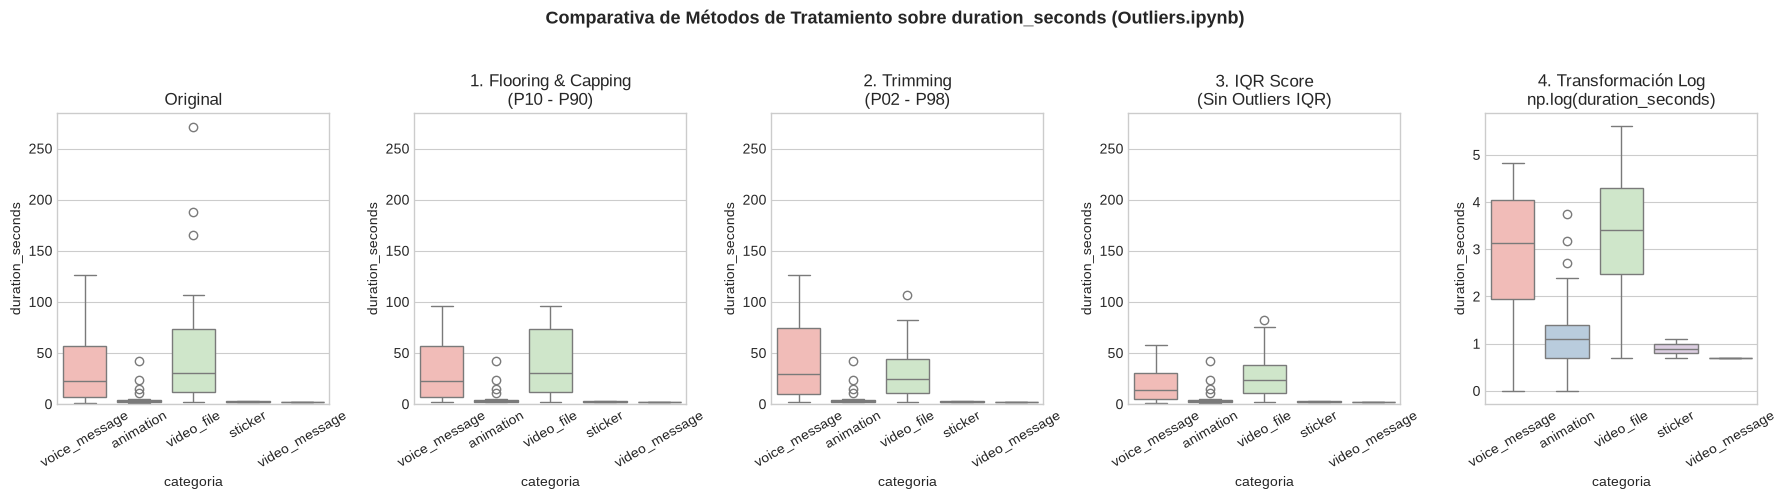

In [21]:
# Comparación visual de los 4 métodos de tratamiento sobre duration_seconds (Box plots antes y después)
fig, axes = plt.subplots(1, 5, figsize=(18, 4.8))

ylim_orig = (0, df_dur['duration_seconds'].max() * 1.05)

sns.boxplot(x='categoria', y='duration_seconds', data=df_dur, ax=axes[0], palette='Pastel1')
axes[0].set_title('Original')
axes[0].set_ylim(ylim_orig)
axes[0].tick_params(axis='x', rotation=30)

sns.boxplot(x='categoria', y='duration_seconds', data=df_fc, ax=axes[1], palette='Pastel1')
axes[1].set_title('1. Flooring & Capping\n(P10 - P90)')
axes[1].set_ylim(ylim_orig)
axes[1].tick_params(axis='x', rotation=30)

sns.boxplot(x='categoria', y='duration_seconds', data=df_tr, ax=axes[2], palette='Pastel1')
axes[2].set_title('2. Trimming\n(P02 - P98)')
axes[2].set_ylim(ylim_orig)
axes[2].tick_params(axis='x', rotation=30)

sns.boxplot(x='categoria', y='duration_seconds', data=df_iqr, ax=axes[3], palette='Pastel1')
axes[3].set_title('3. IQR Score\n(Sin Outliers IQR)')
axes[3].set_ylim(ylim_orig)
axes[3].tick_params(axis='x', rotation=30)

sns.boxplot(x='categoria', y='duration_seconds', data=df_log, ax=axes[4], palette='Pastel1')
axes[4].set_title('4. Transformación Log\nnp.log(duration_seconds)')
axes[4].tick_params(axis='x', rotation=30)

plt.suptitle('Comparativa de Métodos de Tratamiento sobre duration_seconds (Outliers.ipynb)', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

### Conclusión General del Proyecto (TP3)

1. Estructura e Integridad de la Base de Datos Documental:
   - La exportación JSON de Telegram (53.854 registros y 30 campos) refleja un esquema semi-estructurado donde conviven mensajes conversacionales (93,34%) y eventos de servicio (6,66% distribuidos en 8 acciones administrativas como invite_members, remove_members y pin_message).
2. Tratamiento de Valores Faltantes sin Sesgo de Selección:
   - La ausencia de datos en los 22 campos de metadatos opcionales (>72% de nulos) es estructural (dependiente del subtipo de mensaje), mientras que en los campos de autoría se logró recuperar el 100% de from_id mediante consolidación determinística con actor_id, e imputar las cuentas dadas de baja en from mediante la constante global 'Cuenta Eliminada', evitando atribuir mensajes falsamente a la moda.
3. Naturaleza de los Valores Atípicos:
   - Los valores extremos detectados mediante el criterio de rango intercuartílico (IQR) en width (7 casos), height (11 casos), duration_seconds (13 casos) y edited_unixtime (18 casos) no responden a errores de carga ni corrupción de datos, sino a varianza real del dominio (capturas de pantalla en monitores 2K/ultrawide o verticales de teléfonos móviles, y notas de voz o videos demostrativos extensos de soporte técnico). Por ello, deben preservarse para análisis descriptivos o tratarse mediante transformación logarítmica / capping suave si se alimentan modelos sensibles a asimetría.